# 2장. ML 최소 개념

In [1]:
# [준비 셀] 모든 노트북의 첫 코드 셀입니다. 항상 먼저 실행하세요.
from pathlib import Path
import sys

ROOT = Path.cwd().resolve().parents[1]          # docs/manual → 프로젝트 루트
assert (ROOT / "src/bearing_kd").exists(), "docs/manual 폴더에서 노트북을 열어야 합니다"
CODE = ROOT / "docs/manual/code"                 # 챕터별 완성 스크립트 위치
sys.path.insert(0, str(CODE))                    # 스크립트의 함수를 import 해서 쓰기 위해
print("프로젝트 루트 확인 완료:", ROOT.name)

프로젝트 루트 확인 완료: vib-onnx


이 장은 이후 챕터를 읽는 데 꼭 필요한 개념만 다룹니다. 진동 데이터 대신 **2차원 점**이라는 아주 단순한 예제로, 모델이 배우는 과정을 처음부터 끝까지 직접 돌려 봅니다.

| 용어 | 한 줄 설명 |
|---|---|
| 분류(classification) | 입력을 보고 정해진 종류 중 하나를 고르는 문제. 여기서는 정상(0)/고장(1) |
| 모델 | 입력 → 점수를 계산하는 함수. 안에 숫자(가중치)가 잔뜩 들어 있다 |
| 학습 | 정답을 맞히도록 가중치를 조금씩 고치는 과정 |
| logits | 모델이 내놓는 날것의 점수. 클수록 그 종류일 가능성이 높다 |
| softmax | logits를 합이 1인 확률로 바꾸는 함수 |
| loss | 예측이 정답과 얼마나 다른지 나타내는 숫자. 작을수록 좋다 |
| batch | 한 번에 묶어서 학습하는 샘플 수 |
| epoch | 학습 데이터 전체를 한 바퀴 도는 것 |

## 2.1 데이터 만들기

정상은 (0, 0) 근처, 고장은 (2, 2) 근처에 흩어진 점 600개를 만듭니다.

In [2]:
import numpy as np
import torch
import ch02_ml_basics as ch02

x, y = ch02.make_data()
print("입력 x:", tuple(x.shape), "  ← 점 600개, 각 점은 숫자 2개")
print("정답 y:", tuple(y.shape), "  ← 0(정상) 또는 1(고장)")
print("앞 3개:", x[:3].numpy().round(2).tolist(), y[:3].tolist())

입력 x: (600, 2)   ← 점 600개, 각 점은 숫자 2개
정답 y: (600,)   ← 0(정상) 또는 1(고장)
앞 3개: [[1.3300000429153442, 1.5499999523162842], [1.1200000047683716, 2.559999942779541], [-1.1799999475479126, -0.8100000023841858]] [1, 1, 0]


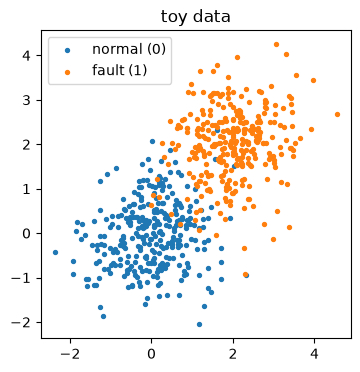

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(4, 4))
plt.scatter(x[y == 0, 0], x[y == 0, 1], s=8, label="normal (0)")
plt.scatter(x[y == 1, 0], x[y == 1, 1], s=8, label="fault (1)")
plt.legend(); plt.title("toy data"); plt.show()

## 2.2 train / validation / test 로 나누기

모델이 **처음 보는 데이터**에서도 잘하는지가 중요합니다. 그래서 데이터를 세 덩어리로 나눕니다.

| 세트 | 용도 | 비유 |
|---|---|---|
| **train** | 가중치를 고치는 데 쓴다 | 교과서 연습문제 |
| **validation** | 학습 중간중간 성능을 보고, 가장 좋은 시점을 고른다 | 모의고사 |
| **test** | 마지막에 딱 한 번 최종 성능을 잰다 | 수능 |

test를 보고 모델을 고치면 "수능 문제를 미리 보고 공부한 것"이 되어 성능이 부풀려집니다.

In [4]:
train_set, valid_set, test_set = ch02.split(x, y)
print("train", len(train_set[0]), "/ validation", len(valid_set[0]), "/ test", len(test_set[0]))

train 420 / validation 90 / test 90


## 2.3 모델: 선형 분류기

가장 단순한 모델은 `점수 = 입력 × 가중치 + 편향`입니다. 입력이 2개, 출력(종류별 점수)이 2개이므로 가중치는 2×2, 편향은 2개, 모두 6개의 숫자입니다.

> 뒤에서 만들 Student의 "분류 헤드"가 바로 이런 선형층입니다. 입력이 512개일 뿐입니다(512×2 + 2 = 1,026개).

In [5]:
torch.manual_seed(42)
model = torch.nn.Linear(2, 2)
print("가중치:", model.weight.data.numpy().round(3).tolist())
print("편향:", model.bias.data.numpy().round(3).tolist())
print("학습할 숫자 개수:", sum(p.numel() for p in model.parameters()))

logits = model(x[:3])
print("\n학습 전 logits:\n", logits.detach().numpy().round(3))

가중치: [[0.5410000085830688, 0.5870000123977661], [-0.16599999368190765, 0.6499999761581421]]
편향: [-0.1550000011920929, 0.14300000667572021]
학습할 숫자 개수: 6

학습 전 logits:
 [[ 1.478  0.931]
 [ 1.955  1.62 ]
 [-1.268 -0.19 ]]


## 2.4 logits → softmax → 예측

- **logits**: `[1.2, -0.5]` 같은 날것의 점수
- **softmax**: `exp(점수)`를 합이 1이 되도록 나눈 값 → `[0.85, 0.15]` = "정상일 확률 85%"
- **예측**: 가장 큰 값의 위치(`argmax`) → 0 (정상)

In [6]:
logits = torch.tensor([[1.2, -0.5]])
probs = torch.softmax(logits, dim=1)
print("logits", logits.tolist(), "→ softmax", probs.numpy().round(3).tolist(), "→ 예측", logits.argmax(1).item())
# 직접 계산해도 같다
e = np.exp([1.2, -0.5]); print("직접 계산:", (e / e.sum()).round(3))

logits [[1.2000000476837158, -0.5]] → softmax [[0.8460000157356262, 0.15399999916553497]] → 예측 0
직접 계산: [0.846 0.154]


## 2.5 loss: 얼마나 틀렸나

분류에서는 **cross-entropy**를 씁니다. 정답 종류의 확률이 `p`일 때 loss는 `-log(p)`입니다.
- 정답 확률 0.9 → loss 0.105 (잘 맞힘)
- 정답 확률 0.5 → loss 0.693 (반반 찍음)
- 정답 확률 0.1 → loss 2.303 (크게 틀림)

In [7]:
import torch.nn.functional as F

for p in (0.9, 0.5, 0.1):
    logit = torch.log(torch.tensor([[p, 1 - p]]))   # softmax 결과가 [p, 1-p]가 되는 logits
    print(f"정답(0) 확률 {p} → loss {F.cross_entropy(logit, torch.tensor([0])).item():.3f}")

정답(0) 확률 0.9 → loss 0.105
정답(0) 확률 0.5 → loss 0.693
정답(0) 확률 0.1 → loss 2.303


## 2.6 학습 루프: 딥러닝의 심장

모든 딥러닝 학습은 아래 다섯 줄의 반복입니다. 9장의 Teacher 학습도 똑같습니다.

```python
logits = model(x_batch)                    # 1) 예측 (forward)
loss = F.cross_entropy(logits, y_batch)    # 2) 얼마나 틀렸나 (loss)
optimizer.zero_grad()                      # 3) 지난번 기울기 지우기
loss.backward()                            # 4) 각 가중치를 어느 쪽으로 고칠지 계산 (backward)
optimizer.step()                           # 5) 가중치를 조금 고치기
```

- **기울기(gradient)**: "이 가중치를 조금 올리면 loss가 얼마나 변하나"
- **optimizer**: 기울기를 보고 가중치를 고치는 규칙. `lr`(learning rate)은 한 번에 얼마나 크게 고칠지
- **batch 32**: 32개씩 묶어서 한 번 고침. **epoch**: train 전체를 한 바퀴

In [8]:
torch.manual_seed(42)
model = torch.nn.Linear(2, 2)
ch02.train(model, train_set, valid_set, epochs=20, batch_size=32, lr=0.1)

  epoch  1  loss 0.6355  train 0.771  valid 0.733
  epoch  2  loss 0.3967  train 0.852  valid 0.867
  epoch  3  loss 0.3217  train 0.902  valid 0.944
  epoch  5  loss 0.2485  train 0.931  valid 0.956
  epoch 10  loss 0.1813  train 0.955  valid 0.956
  epoch 15  loss 0.1565  train 0.957  valid 0.956
  epoch 20  loss 0.1433  train 0.960  valid 0.967


Linear(in_features=2, out_features=2, bias=True)

loss는 줄고 train·validation 정확도는 함께 올라갑니다. 둘이 같이 오르면 **규칙을 배우고 있다**는 뜻입니다.

## 2.7 평가: 정확도와 혼동행렬

정확도 하나만 보면 **어떤 실수를 했는지** 알 수 없습니다. 혼동행렬은 실제/예측 조합별 개수입니다.

|  | 예측 정상 | 예측 고장 |
|---|---|---|
| **실제 정상** | 맞음 | **오경보** (정상인데 고장이라 함) |
| **실제 고장** | **놓침** (고장인데 정상이라 함) | 맞음 |

베어링 진단에서는 **놓침**이 가장 위험합니다.

In [9]:
with torch.no_grad():
    pred = model(test_set[0]).argmax(1)
print("test 정확도:", (pred == test_set[1]).float().mean().item())
print("혼동행렬 [[정상→정상, 정상→고장], [고장→정상, 고장→고장]]")
print(ch02.confusion(pred, test_set[1]))

test 정확도: 0.9444444179534912
혼동행렬 [[정상→정상, 정상→고장], [고장→정상, 고장→고장]]
[[47  1]
 [ 4 38]]


## 2.8 오버피팅: 외우기 vs 이해하기

모델이 규칙 대신 **학습 데이터 자체를 외우면** train은 잘하는데 처음 보는 데이터는 못합니다. 이것이 **오버피팅**입니다.

아래는 일부러 정답을 무작위로 섞어서 "배울 규칙이 없는" 데이터를 만들고, 큰 모델로 학습시킨 것입니다.

In [10]:
g = torch.Generator().manual_seed(42)
y_random = y[torch.randperm(len(y), generator=g)]
small_train, random_valid = (x[:60], y_random[:60]), (x[420:510], y_random[420:510])

torch.manual_seed(42)
big = torch.nn.Sequential(torch.nn.Linear(2, 256), torch.nn.ReLU(), torch.nn.Linear(256, 256),
                          torch.nn.ReLU(), torch.nn.Linear(256, 2))
opt = torch.optim.Adam(big.parameters(), lr=1e-2)
for _ in range(1500):
    loss = F.cross_entropy(big(small_train[0]), small_train[1])
    opt.zero_grad(); loss.backward(); opt.step()

print("train 정확도", round(ch02.accuracy(big, small_train), 3), "← 외워서 100%")
print("valid 정확도", round(ch02.accuracy(big, random_valid), 3), "← 처음 보는 데이터는 찍는 수준")

train 정확도 1.0 ← 외워서 100%
valid 정확도 0.511 ← 처음 보는 데이터는 찍는 수준


## 2.9 이 프로젝트에서 실제로 일어난 일 (미리 보기)

5장과 12장에서 자세히 보겠지만, 이 프로젝트의 첫 모델도 비슷한 함정에 빠졌습니다.

| 평가 방식 | 결과 |
|---|---|
| 같은 베어링의 **다른 파일**로 test | 99.6% |
| **처음 보는 베어링**으로 test | 58~65% |

모델이 "고장의 특징"보다 **"각 베어링 개체의 특징"을 외웠기** 때문입니다. validation/test를 어떻게 나누느냐가 모델 성능만큼 중요하다는 것을 기억하세요.

## 2장 완성 코드: `code/ch02_ml_basics.py`
```bash
python docs/manual/code/ch02_ml_basics.py
```

In [11]:
from IPython.display import Code
Code(filename=str(CODE / "ch02_ml_basics.py"), language="python")

"""2장 완성 코드: 가장 작은 분류 모델을 처음부터 학습해 보면서 ML 기본 개념을 확인한다.

- 가짜 데이터(점 2개 묶음)를 만들고
- train / validation / test로 나누고
- 선형 분류기를 epoch, batch 단위로 학습하고
- logits → softmax → 정확도, 혼동행렬로 평가한다.
- 마지막으로 "정답을 무작위로 섞은" 데이터로 오버피팅을 눈으로 확인한다.

실행 (프로젝트 루트에서):
    python docs/manual/code/ch02_ml_basics.py
"""

import numpy as np
import torch
import torch.nn.functional as F

SEED = 42


def make_data(n=600, seed=SEED):
    """정상(0)은 (0,0) 근처, 고장(1)은 (2,2) 근처에 흩어진 2차원 점."""
    rng = np.random.default_rng(seed)
    x0 = rng.normal(0.0, 0.8, size=(n // 2, 2))
    x1 = rng.normal(2.0, 0.8, size=(n // 2, 2))
    x = np.concatenate([x0, x1]).astype(np.float32)
    y = np.array([0] * (n // 2) + [1] * (n // 2), dtype=np.int64)
    order = rng.permutation(n)
    return torch.from_numpy(x[order]), torch.from_numpy(y[order])


def split(x, y, train=0.7, valid=0.15):
    a, b = int(len(x) * train), int(len(x) * (train + valid))
    return (x[:a], y[:a]), (x[a:b], y[a:b]), (x[b:], y[b:])


def confusion(pred, true):
    """행 = 실제, 열 = 예측. [[정상→정상, 정상→고장], [고장→정상, 고장→고장]]"""
    m = np.zeros((2, 2), dtype=int)
    for p, t in zip(pred.tolist(), true.tolist()):
        m[t, p] += 1
    return m


def train(model, train_set, valid_set, epochs=20, batch_size=32, lr=0.1, verbose=True):
    torch.manual_seed(SEED)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    x_train, y_train = train_set
    for epoch in range(1, epochs + 1):
        model.train()
        order = torch.randperm(len(x_train))          # 매 epoch마다 순서를 섞는다
        total = 0.0
        for start in range(0, len(order), batch_size):  # batch 단위로 잘라서
            idx = order[start:start + batch_size]
            logits = model(x_train[idx])                # 1) 예측 (forward)
            loss = F.cross_entropy(logits, y_train[idx])  # 2) 얼마나 틀렸는지 (loss)
            optimizer.zero_grad()                       # 3) 이전 기울기 지우기
            loss.backward()                             # 4) 기울기 계산 (backward)
            optimizer.step()                            # 5) 가중치 수정
            total += loss.item() * len(idx)
        train_acc = accuracy(model, train_set)
        valid_acc = accuracy(model, valid_set)
        if verbose and (epoch <= 3 or epoch % 5 == 0):
            print(f"  epoch {epoch:2d}  loss {total / len(x_train):.4f}  train {train_acc:.3f}  valid {valid_acc:.3f}")
    return model


@torch.no_grad()
def accuracy(model, data):
    model.eval()
    x, y = data
    return (model(x).argmax(1) == y).float().mean().item()


def main():
    x, y = make_data()
    train_set, valid_set, test_set = split(x, y)
    print(f"데이터: train {len(train_set[0])}, validation {len(valid_set[0])}, test {len(test_set[0])}")

    print("\n[1] 선형 분류기 학습 (입력 2개 → 점수 2개)")
    torch.manual_seed(SEED)
    model = torch.nn.Linear(2, 2)
    train(model, train_set, valid_set)

    with torch.no_grad():
        logits = model(test_set[0])
    probs = torch.softmax(logits, dim=1)
    pred = logits.argmax(1)
    print("\n[2] test 평가")
    print(f"  첫 샘플 logits {logits[0].numpy().round(3)} → softmax 확률 {probs[0].numpy().round(3)} → 예측 {pred[0].item()}")
    print(f"  정확도 {(pred == test_set[1]).float().mean().item():.3f}")
    print(f"  혼동행렬 [[정상→정상, 정상→고장], [고장→정상, 고장→고장]]\n{confusion(pred, test_set[1])}")

    print("\n[3] 오버피팅 체험: 정답을 무작위로 섞으면 배울 규칙이 없다")
    g = torch.Generator().manual_seed(SEED)
    y_random = y[torch.randperm(len(y), generator=g)]
    small_train = (x[:60], y_random[:60])                  # 작은 데이터 + 큰 모델
    random_valid = (x[420:510], y_random[420:510])
    torch.manual_seed(SEED)
    big = torch.nn.Sequential(torch.nn.Linear(2, 256), torch.nn.ReLU(), torch.nn.Linear(256, 256),
                              torch.nn.ReLU(), torch.nn.Linear(256, 2))
    optimizer = torch.optim.Adam(big.parameters(), lr=1e-2)
    for _ in range(1500):
        loss = F.cross_entropy(big(small_train[0]), small_train[1])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    print(f"  t